In [1]:
import pandas as pd

In [2]:
source_file = r"C:\Divyesh\Technoval Forecasting\Cleaned_sales_data.parquet"
original_data = pd.read_parquet(source_file)

In [3]:
# Creating a sample file and an unique values file for reference
sample_file = r"C:\Divyesh\Technoval Forecasting\references\Sales_data_sample.xlsx"

original_data.head(100).to_excel(
    sample_file, sheet_name="Sales Data", index=False
)

# Unique values only (one list per column, not full rows).
# Columns have different lengths, so shorter lists are padded with blanks.
unique_file = r"C:\Divyesh\Technoval Forecasting\references\Unique_values.xlsx"
unique_columns = [
    "Manufacturer or Trading",
    "Product Family",
    "Customer Type",
    "Customer",
    "Territory",
    "Company",
]

unique_values = {
    column: sorted(original_data[column].dropna().astype(str).unique())
    for column in unique_columns
}
max_len = max(len(values) for values in unique_values.values())
unique_df = pd.DataFrame(
    {
        column: values + [pd.NA] * (max_len - len(values))
        for column, values in unique_values.items()
    }
)
unique_df.to_excel(unique_file, sheet_name="Unique Values", index=False)

print(f"Saved sample: {sample_file}")
print(f"Saved unique values: {unique_file}")
for column in unique_columns:
    print(f"{column}: {len(unique_values[column])} unique")

Saved sample: C:\Divyesh\Technoval Forecasting\references\Sales_data_sample.xlsx
Saved unique values: C:\Divyesh\Technoval Forecasting\references\Unique_values.xlsx
Manufacturer or Trading: 2 unique
Product Family: 9 unique
Customer Type: 10 unique
Customer: 1993 unique
Territory: 42 unique
Company: 2 unique


In [4]:
# Dataframe information

# print(f"Lenght of the dataframe: {len(original_data)}")
# print(f"Number of columns: {len(original_data.columns)}")
# print(f"Datatypes of the columns: {original_data.dtypes}")
print(f"Null values in the dataframe: {original_data.isna().sum()}")
# original_data.info()
# original_data.sample(10) 
original_data["Manufacturer or Trading"].unique()

Null values in the dataframe: Company                    0
Territory                  0
Customer                   0
Customer Type              0
InvDate                    0
NetAmt                     0
qtynos                     0
Product Family             0
Manufacturer or Trading    0
Year                       0
Month                      0
dtype: int64


<ArrowStringArray>
['MFG', 'TRD']
Length: 2, dtype: string

## Step 2 - Build monthly sales series

Following cell independently to read `Cleaned_sales_data.parquet` and save `Monthly_sales.parquet`. Set `last_complete_month` if the latest source month is partial. Missing months are treated as zero sales only under the assumption that the source covers those months. Territory/type ties use alphabetical order; conflicts remain available in `attribute_conflicts` for EDA.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

In [6]:
project_dir = Path(r"C:\Divyesh\Technoval Forecasting")
monthly_source_file = project_dir / "Cleaned_sales_data.parquet"
monthly_output_file = project_dir / "Monthly_sales.parquet"

In [7]:

# None follows the roadmap: include the latest month in the source.
# If that month is incomplete, set the last COMPLETE month, e.g. "2026-10-01".
last_complete_month = None


def build_monthly_series(cleaned_sales, last_complete_month=None):
    series_keys = ["Company", "Customer", "Product Family", "Manufacturer or Trading"]
    attributes = ["Territory", "Customer Type"]
    required = series_keys + attributes + ["InvDate", "qtynos", "NetAmt"]
    missing_columns = sorted(set(required) - set(cleaned_sales.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")
    sales = cleaned_sales[required].copy()
    if sales[series_keys].isna().any().any():
        raise ValueError("Missing series keys: resolve them in Step 1 before aggregation.")
    sales["Month"] = pd.to_datetime(sales["InvDate"], errors="raise").dt.to_period("M").dt.to_timestamp()
    for column in ["qtynos", "NetAmt"]:
        sales[column] = pd.to_numeric(sales[column], errors="raise")
    if sales[["Month", "qtynos", "NetAmt"]].isna().any().any():
        raise ValueError("Cleaned data contains missing dates, quantities, or amounts.")
    if not np.isfinite(sales[["qtynos", "NetAmt"]].to_numpy(dtype=float)).all():
        raise ValueError("Quantities and amounts must be finite numbers.")
    if sales.empty:
        raise ValueError("No cleaned sales rows are available.")

    end_month = sales["Month"].max()
    if last_complete_month is not None:
        end_month = min(end_month, pd.Timestamp(last_complete_month).to_period("M").to_timestamp())
        sales = sales.loc[sales["Month"] <= end_month].copy()
    if sales.empty:
        raise ValueError("No sales rows remain before the selected cutoff.")

    # Most frequent non-missing attribute per observed month; alphabetical tie-break.
    def most_frequent(values):
        modes = values.dropna().mode()
        return modes.iloc[0] if not modes.empty else pd.NA

    group_keys = series_keys + ["Month"]
    observed = sales.groupby(group_keys, observed=True, sort=True).agg(
        qty=("qtynos", "sum"),
        net_amt=("NetAmt", "sum"),
        invoice_count=("qtynos", "size"),  # Row count, not distinct invoices.
        **{column: (column, most_frequent) for column in attributes},
    ).reset_index()

    # Flag conflicting attributes across the history for later EDA.
    conflicts = sales.groupby(series_keys, observed=True)[attributes].nunique(dropna=True)
    conflicts = conflicts.loc[conflicts.gt(1).any(axis=1)].reset_index()
    conflicts = conflicts.rename(columns={column: f"{column}_distinct_count" for column in attributes})

    # Each series begins at its own first observed month; all end together.
    calendar = observed.groupby(series_keys, observed=True)["Month"].min().reset_index()
    calendar["Month"] = calendar["Month"].map(lambda start: pd.date_range(start, end_month, freq="MS"))
    calendar = calendar.explode("Month", ignore_index=True)
    calendar["Month"] = pd.to_datetime(calendar["Month"])
    monthly = calendar.merge(observed, on=group_keys, how="left", validate="one_to_one", indicator=True)
    inserted = monthly.pop("_merge").eq("left_only")
    monthly.loc[inserted, ["qty", "net_amt", "invoice_count"]] = 0
    monthly["invoice_count"] = monthly["invoice_count"].astype("int64")
    monthly = monthly.sort_values(group_keys).reset_index(drop=True)
    # Carry the last known attributes into gap months, without looking ahead.
    monthly[attributes] = monthly.groupby(series_keys, observed=True)[attributes].ffill()
    monthly["avg_price"] = monthly["net_amt"].div(monthly["qty"].where(monthly["qty"].ne(0)))
    monthly = monthly[group_keys + attributes + ["qty", "net_amt", "invoice_count", "avg_price"]]

    # Reconcile against the retained invoice rows before writing output.
    np.testing.assert_allclose(monthly["qty"].sum(), sales["qtynos"].sum(), rtol=1e-10, atol=1e-6)
    np.testing.assert_allclose(monthly["net_amt"].sum(), sales["NetAmt"].sum(), rtol=1e-10, atol=1e-6)
    assert monthly["invoice_count"].sum() == len(sales), "Invoice-row count changed."
    assert not monthly.duplicated(group_keys).any(), "Duplicate series-month rows."
    return monthly, conflicts, int(inserted.sum())


# Load explicitly: this cell does not rely on variables from previous cells.
# Missing months are assumed to have no sales; confirm source coverage first.
monthly_input = pd.read_parquet(monthly_source_file)
monthly_sales, attribute_conflicts, zero_months_added = build_monthly_series(
    monthly_input, last_complete_month=last_complete_month
)
monthly_sales.to_parquet(monthly_output_file, index=False)
print(f"Saved: {monthly_output_file}")
print(f"Monthly rows: {len(monthly_sales):,}; zero-sale months inserted: {zero_months_added:,}")
print(f"Month range: {monthly_sales['Month'].min():%Y-%m} to {monthly_sales['Month'].max():%Y-%m}")
print(f"Series with territory/type conflicts: {len(attribute_conflicts):,} (see attribute_conflicts)")
display(monthly_sales.head(10))
display(attribute_conflicts.head(10))


Saved: C:\Divyesh\Technoval Forecasting\Monthly_sales.parquet
Monthly rows: 366,812; zero-sale months inserted: 246,635
Month range: 2018-04 to 2026-09
Series with territory/type conflicts: 615 (see attribute_conflicts)


,Company,Customer,Product Family,Manufacturer or Trading,Month,Territory,Customer Type,qty,net_amt,invoice_count,avg_price
0,TISL,4A SOLUTIONS,TDL,MFG,2020-02-01,Middle East,Export,69000.0,6545505.93,8,94.862405
1,TISL,4A SOLUTIONS,TDL,MFG,2020-03-01,Middle East,Export,0.0,0.00,0,NaN
2,TISL,4A SOLUTIONS,TDL,MFG,2020-04-01,Middle East,Export,0.0,0.00,0,NaN
3,TISL,4A SOLUTIONS,TDL,MFG,2020-05-01,Middle East,Export,0.0,0.00,0,NaN
4,TISL,4A SOLUTIONS,TDL,MFG,2020-06-01,Middle East,Export,0.0,0.00,0,NaN
5,TISL,4A SOLUTIONS,TDL,MFG,2020-07-01,Middle East,Export,0.0,0.00,0,NaN
6,TISL,4A SOLUTIONS,TDL,MFG,2020-08-01,Middle East,Export,0.0,0.00,0,NaN
7,TISL,4A SOLUTIONS,TDL,MFG,2020-09-01,Middle East,Export,0.0,0.00,0,NaN
8,TISL,4A SOLUTIONS,TDL,MFG,2020-10-01,Middle East,Export,0.0,0.00,0,NaN
9,TISL,4A SOLUTIONS,TDL,MFG,2020-11-01,Middle East,Export,0.0,0.00,0,NaN


,Company,Customer,Product Family,Manufacturer or Trading,Territory_distinct_count,Customer Type_distinct_count
0,TISL,A.R.ENTERPRISES - KOLKATA (NSG) D,ANG,MFG,1,2
1,TISL,A.R.ENTERPRISES - KOLKATA (NSG) D,ICTP,MFG,1,2
2,TISL,AAJ KA ANAND PAPERS LTD (NSG),VIO,MFG,1,2
3,TISL,AAJ KA ANAND PAPERS LTD (NSG),VIO,TRD,1,2
4,TISL,ABHINAV GRAPHICS & PAPERS PVT LTD NSG-D,ANG,MFG,1,2
5,TISL,ABHINAV GRAPHICS & PAPERS PVT LTD NSG-D,ICTP,MFG,1,2
6,TISL,ABP IMAGING TECHNOLOGIES PVT.LTD-NSG HYD,VIO,MFG,1,2
7,TISL,ABP PVT. LTD,TDL,MFG,1,2
8,TISL,ABP PVT. LTD,VIO,MFG,1,2
9,TISL,AMAR UJALA LIMITED - BAREILLY,DOP,TRD,1,2


## Step 3 — EDA and source-coverage check

Run this section after Step 2. Review invoice-date coverage before modeling. The cutoff cell uses a conservative month-end date heuristic; override the cutoff only when you have verified source completeness.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

project_dir = Path(r"C:\Divyesh\Technoval Forecasting")
monthly_source_file = project_dir / "Cleaned_sales_data.parquet"
monthly_output_file = project_dir / "Monthly_sales.parquet"
series_keys = ["Company", "Customer", "Product Family", "Manufacturer or Trading"]
attribute_columns = ["Territory", "Customer Type"]

cleaned_sales = pd.read_parquet(monthly_source_file)
monthly_sales = pd.read_parquet(monthly_output_file)
cleaned_sales["InvDate"] = pd.to_datetime(cleaned_sales["InvDate"], errors="raise")
monthly_sales["Month"] = pd.to_datetime(monthly_sales["Month"], errors="raise").dt.to_period("M").dt.to_timestamp()

source_monthly_coverage = (
    cleaned_sales.assign(Month=cleaned_sales["InvDate"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month", as_index=False)
    .agg(
        invoice_rows=("InvDate", "size"),
        first_invoice=("InvDate", "min"),
        last_invoice=("InvDate", "max"),
        qty=("qtynos", "sum"),
        net_amt=("NetAmt", "sum"),
    )
)
latest_source_date = cleaned_sales["InvDate"].max().normalize()
latest_source_month = latest_source_date.to_period("M").to_timestamp()
calendar_month_end = latest_source_month + pd.offsets.MonthEnd(0)

# Override only after confirming the source feed is complete through that month.
manual_forecast_cutoff_month = None  # Example: "2026-09-01"
if manual_forecast_cutoff_month is not None:
    forecast_cutoff_month = pd.Timestamp(manual_forecast_cutoff_month).to_period("M").to_timestamp()
else:
    forecast_cutoff_month = (
        latest_source_month
        if latest_source_date == calendar_month_end
        else latest_source_month - pd.offsets.MonthBegin(1)
    )

if forecast_cutoff_month not in set(monthly_sales["Month"]):
    raise ValueError(f"Cutoff {forecast_cutoff_month:%Y-%m} is not present in Monthly_sales.parquet.")
analysis_monthly = monthly_sales.loc[monthly_sales["Month"] <= forecast_cutoff_month].copy()
if analysis_monthly.empty:
    raise ValueError("No monthly rows remain at the selected forecast cutoff.")

print(f"Invoice-level rows: {len(cleaned_sales):,}")
print(f"Source date range: {cleaned_sales['InvDate'].min():%Y-%m-%d} to {latest_source_date:%Y-%m-%d}")
print(f"Latest source month: {latest_source_month:%Y-%m}; latest invoice day: {latest_source_date.day}")
print(f"Selected cutoff: {forecast_cutoff_month:%Y-%m} (override manually only after checking feed completeness)")
print(f"Analysis panel: {len(analysis_monthly):,} rows; {analysis_monthly[series_keys].drop_duplicates().shape[0]:,} series; {analysis_monthly['Month'].min():%Y-%m} to {analysis_monthly['Month'].max():%Y-%m}")
display(source_monthly_coverage.tail(12))

Invoice-level rows: 652,425
Source date range: 2018-04-30 to 2026-09-30
Latest source month: 2026-09; latest invoice day: 30
Selected cutoff: 2026-09 (override manually only after checking feed completeness)
Analysis panel: 366,812 rows; 5,059 series; 2018-04 to 2026-09


,Month,invoice_rows,first_invoice,last_invoice,qty,net_amt
90,2025-10-01,6206,2025-10-31,2025-10-31,5496358,8.963182e+08
91,2025-11-01,6363,2025-11-30,2025-11-30,5815438,9.844759e+08
92,2025-12-01,7013,2025-12-31,2025-12-31,6996416,1.169869e+09
93,2026-01-01,6582,2026-01-31,2026-01-31,6177723,1.079117e+09
94,2026-02-01,6339,2026-02-28,2026-02-28,5637270,1.003685e+09
95,2026-03-01,6694,2026-03-31,2026-03-31,6237091,1.125001e+09
96,2026-04-01,5335,2026-04-30,2026-04-30,5000907,9.547127e+08
97,2026-05-01,4820,2026-05-31,2026-05-31,4471319,8.780220e+08
98,2026-06-01,5195,2026-06-30,2026-06-30,5007773,9.910901e+08
99,2026-07-01,5104,2026-07-31,2026-07-31,4942019,9.848092e+08


Company contribution and latest 12 months vs prior 12 months


,Company,qty,net_amt,recent_12m_qty,recent_12m_net_amt,prior_12m_qty,prior_12m_net_amt,qty_share_pct,net_amt_share_pct,qty_yoy_change_pct,net_amt_yoy_change_pct
0,TISL,610933343.0,8.589490e+10,65017771.0,1.187058e+10,74642978.0,1.178205e+10,99.370057,99.50785,-12.894993,0.751384
1,TISL - DUBAI,3872927.0,4.248225e+08,147120.0,2.862674e+07,178220.0,3.133439e+07,0.629943,0.49215,-17.450342,-8.641149


Top territories


,Territory,qty,net_amt,recent_12m_qty,recent_12m_net_amt,prior_12m_qty,prior_12m_net_amt,qty_share_pct,net_amt_share_pct,qty_yoy_change_pct,net_amt_yoy_change_pct
24,New Delhi,82443461.0,1.353550e+10,7804221.0,1.744654e+09,10221665.0,1.944323e+09,13.409665,15.680653,-23.650198,-10.269299
38,Uttar Pradesh (W),55176596.0,6.431961e+09,6000197.0,8.920512e+08,6100836.0,8.161387e+08,8.974631,7.451323,-1.649594,9.301422
21,Mumbai,50897569.0,7.497168e+09,5450950.0,1.072976e+09,6455275.0,1.075081e+09,8.278635,8.685348,-15.558206,-0.195772
27,PKG,40176120.0,4.996588e+09,4706834.0,7.424893e+08,5601621.0,7.596571e+08,6.534761,5.788466,-15.973715,-2.259944
28,Punjab / Haryana,40061737.0,5.366998e+09,3858413.0,6.760606e+08,4735636.0,7.010650e+08,6.516156,6.217580,-18.523869,-3.566631
3,Andhra Pradesh,39273820.0,5.757625e+09,3550798.0,6.832564e+08,4101424.0,7.055810e+08,6.387999,6.670116,-13.425240,-3.164009
35,TN( Chennai),35936568.0,5.466504e+09,4423196.0,8.444823e+08,4748674.0,7.861247e+08,5.845186,6.332856,-6.854082,7.423448
13,Gujarat,32430462.0,4.828692e+09,3208709.0,6.447063e+08,3960841.0,6.657479e+08,5.274907,5.593961,-18.989200,-3.160602
29,Rajasthan,28677079.0,3.983011e+09,3371622.0,5.673166e+08,3554216.0,5.249358e+08,4.664409,4.614254,-5.137392,8.073525
16,Karnataka,27748626.0,3.903498e+09,3126317.0,5.540511e+08,3559144.0,5.483381e+08,4.513393,4.522140,-12.160986,1.041878


Customer types


,Customer Type,qty,net_amt,recent_12m_qty,recent_12m_net_amt,prior_12m_qty,prior_12m_net_amt,qty_share_pct,net_amt_share_pct,qty_yoy_change_pct,net_amt_yoy_change_pct
2,Direct Customer,211730414.0,3.132814e+10,32174269.0,5.523777e+09,32410071.0,4.979156e+09,34.438558,36.293145,-0.727558,10.938037
1,Dealer,181242777.0,2.650981e+10,21683697.0,4.108381e+09,27115563.0,4.305376e+09,29.479657,30.711181,-20.032282,-4.575563
4,MLP,101338148.0,1.440743e+10,6481138.0,1.387163e+09,10372197.0,1.806623e+09,16.482940,16.690776,-37.514318,-23.217902
9,Wings,79056054.0,8.861383e+09,1176181.0,1.926810e+08,738417.0,9.982862e+07,12.858694,10.265769,59.284117,93.011785
3,Export,24997383.0,3.100679e+09,2040270.0,3.972136e+08,2098060.0,3.196506e+08,4.065896,3.592086,-2.754449,24.264918
6,OEM parties,16334893.0,2.104794e+09,1609336.0,2.899916e+08,2086890.0,3.027529e+08,2.656917,2.438370,-22.883525,-4.215089
8,Vendor,68691.0,5.753046e+06,0.0,0.000000e+00,0.0,0.000000e+00,0.011173,0.006665,NaN,NaN
0,..,36500.0,1.302246e+06,0.0,0.000000e+00,0.0,0.000000e+00,0.005937,0.001509,NaN,NaN
5,Non-Graphic Customer,1310.0,4.087200e+05,0.0,0.000000e+00,0.0,0.000000e+00,0.000213,0.000473,NaN,NaN
7,SECONDARY TRANPORTATION,100.0,2.253539e+04,0.0,0.000000e+00,0.0,0.000000e+00,0.000016,0.000026,NaN,NaN


... (7 outputs left out)

,calendar_month,mean_monthly_qty,median_monthly_qty,mean_monthly_net_amt
0,1,1781.937873,0.0,247933.724285
1,2,1702.761657,0.0,236889.756663
2,3,1742.209162,0.0,247841.294718
3,4,1702.203378,0.0,238401.611162
4,5,1613.110733,0.0,229878.189444
5,6,1618.916620,0.0,229703.846802
6,7,1586.183063,0.0,227429.049498
7,8,1618.238943,0.0,226221.316552
8,9,1617.897747,0.0,228174.419789
9,10,1669.909287,0.0,228122.809227


Correlation of monthly aggregate quantity and value: 0.568
Intermittency distribution


,zero_month_share
count,5059.000000
mean,0.650979
std,0.346678
min,0.000000
50%,0.802083
75%,0.952381
90%,0.980392
95%,0.988889
max,1.000000


Series with >=50% zero months: 69.1%; series with no positive-quantity month: 37
Monthly rows with negative net quantity: 769
Top 10 customers' share of net quantity: 13.8%
Series with conflicting Territory or Customer Type in invoice history: 615


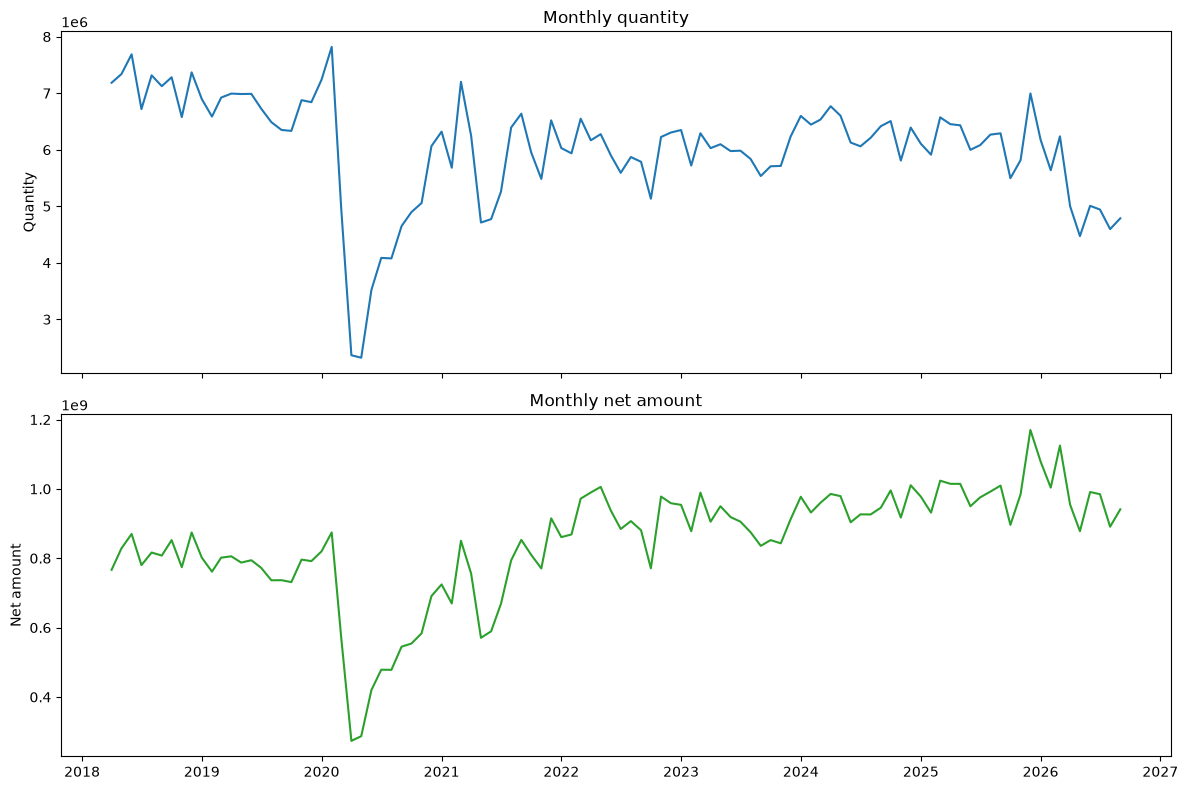

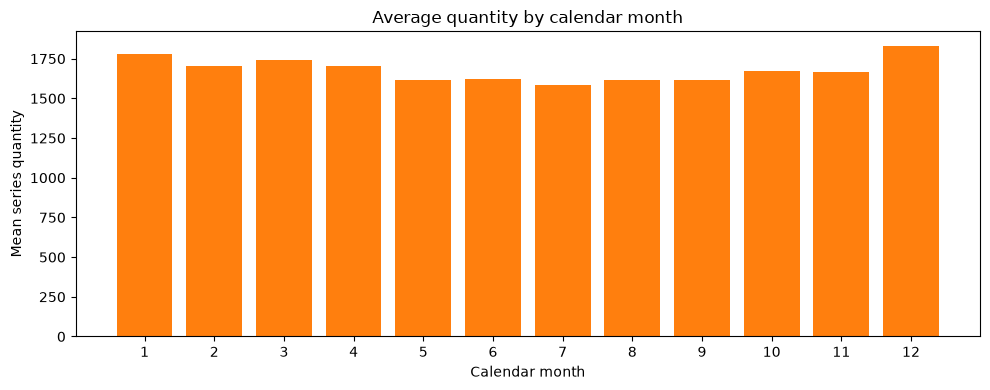

EDA note for the notebook: Coverage: 2018-04 to 2026-09; 5,059 series; zero-month share (median across series) 80.2%; 615 series have conflicting attributes. MFG/TRD quantity shares: MFG 97.4%, TRD 2.6%. Review the contribution/trend tables and plots above before changing the series grain.


In [8]:
# Main EDA tables: contribution, recent trend, product mix, activity, and price/value relationship.
cutoff = forecast_cutoff_month
recent_start = cutoff - pd.DateOffset(months=11)
prior_start = cutoff - pd.DateOffset(months=23)
recent = analysis_monthly.loc[analysis_monthly["Month"].between(recent_start, cutoff)]
prior = analysis_monthly.loc[analysis_monthly["Month"].between(prior_start, cutoff - pd.DateOffset(months=12))]

def contribution_and_trend(column):
    totals = analysis_monthly.groupby(column, dropna=False, as_index=False).agg(qty=("qty", "sum"), net_amt=("net_amt", "sum"))
    recent_totals = recent.groupby(column, dropna=False, as_index=False).agg(recent_12m_qty=("qty", "sum"), recent_12m_net_amt=("net_amt", "sum"))
    prior_totals = prior.groupby(column, dropna=False, as_index=False).agg(prior_12m_qty=("qty", "sum"), prior_12m_net_amt=("net_amt", "sum"))
    result = totals.merge(recent_totals, on=column, how="left").merge(prior_totals, on=column, how="left")
    result["qty_share_pct"] = 100 * result["qty"] / result["qty"].sum() if result["qty"].sum() else np.nan
    result["net_amt_share_pct"] = 100 * result["net_amt"] / result["net_amt"].sum() if result["net_amt"].sum() else np.nan
    result["qty_yoy_change_pct"] = 100 * (result["recent_12m_qty"] - result["prior_12m_qty"]) / result["prior_12m_qty"].abs().replace(0, np.nan)
    result["net_amt_yoy_change_pct"] = 100 * (result["recent_12m_net_amt"] - result["prior_12m_net_amt"]) / result["prior_12m_net_amt"].abs().replace(0, np.nan)
    return result.sort_values("qty", ascending=False)

print("Company contribution and latest 12 months vs prior 12 months")
display(contribution_and_trend("Company"))
print("Top territories")
display(contribution_and_trend("Territory").head(20))
print("Customer types")
display(contribution_and_trend("Customer Type"))
print("Manufacturer vs Trading")
display(contribution_and_trend("Manufacturer or Trading"))

family_territory_qty = analysis_monthly.pivot_table(index="Product Family", columns="Territory", values="qty", aggfunc="sum", fill_value=0, observed=True)
print("Product Family x Territory quantity (top 15 territories by quantity)")
top_territories = analysis_monthly.groupby("Territory")["qty"].sum().nlargest(15).index
display(family_territory_qty.reindex(columns=top_territories))

customer_family = (
    analysis_monthly.groupby(["Customer", "Product Family"], as_index=False, dropna=False)
    .agg(qty=("qty", "sum"), net_amt=("net_amt", "sum"), active_months=("qty", lambda s: int(s.gt(0).sum())))
)
top_customer_names = analysis_monthly.groupby("Customer")["qty"].sum().nlargest(20).index
print("Product families for the 20 largest customers by net quantity")
display(customer_family.loc[customer_family["Customer"].isin(top_customer_names)].sort_values(["Customer", "qty"], ascending=[True, False]))

monthly_totals = analysis_monthly.groupby("Month", as_index=False).agg(qty=("qty", "sum"), net_amt=("net_amt", "sum"))
monthly_totals["realized_avg_price"] = monthly_totals["net_amt"].div(monthly_totals["qty"].where(monthly_totals["qty"].ne(0)))
seasonality = analysis_monthly.assign(calendar_month=analysis_monthly["Month"].dt.month).groupby("calendar_month", as_index=False).agg(mean_monthly_qty=("qty", "mean"), median_monthly_qty=("qty", "median"), mean_monthly_net_amt=("net_amt", "mean"))
print("Calendar-month seasonality across series-month observations")
display(seasonality)
print(f"Correlation of monthly aggregate quantity and value: {monthly_totals[['qty', 'net_amt']].corr().iloc[0, 1]:.3f}")

series_activity = analysis_monthly.groupby(series_keys, observed=True).agg(months=("Month", "size"), zero_month_share=("qty", lambda s: s.eq(0).mean()), positive_months=("qty", lambda s: s.gt(0).sum()), negative_months=("qty", lambda s: s.lt(0).sum())).reset_index()
print("Intermittency distribution")
display(series_activity["zero_month_share"].describe(percentiles=[.5, .75, .9, .95]).to_frame())
print(f"Series with >=50% zero months: {series_activity['zero_month_share'].ge(.5).mean():.1%}; series with no positive-quantity month: {series_activity['positive_months'].eq(0).sum():,}")
print(f"Monthly rows with negative net quantity: {analysis_monthly['qty'].lt(0).sum():,}")
customer_totals = analysis_monthly.groupby("Customer")["qty"].sum().sort_values(ascending=False)
net_quantity = analysis_monthly["qty"].sum()
print(f"Top 10 customers' share of net quantity: {100 * customer_totals.head(10).sum() / net_quantity:.1f}%" if net_quantity else "Net quantity total is zero; top-customer share is undefined.")

# Attribute conflicts were retained during Step 2; count series with changing labels.
attribute_conflict_check = cleaned_sales.groupby(series_keys, observed=True)[attribute_columns].nunique(dropna=True)
attribute_conflict_count = int(attribute_conflict_check.gt(1).any(axis=1).sum())
print(f"Series with conflicting Territory or Customer Type in invoice history: {attribute_conflict_count:,}")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(monthly_totals["Month"], monthly_totals["qty"], color="tab:blue")
axes[0].set_title("Monthly quantity")
axes[0].set_ylabel("Quantity")
axes[1].plot(monthly_totals["Month"], monthly_totals["net_amt"], color="tab:green")
axes[1].set_title("Monthly net amount")
axes[1].set_ylabel("Net amount")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(seasonality["calendar_month"], seasonality["mean_monthly_qty"], color="tab:orange")
ax.set(xticks=range(1, 13), xlabel="Calendar month", ylabel="Mean series quantity", title="Average quantity by calendar month")
plt.tight_layout()
plt.show()

eda_note = (
    f"Coverage: {analysis_monthly['Month'].min():%Y-%m} to {cutoff:%Y-%m}; "
    f"{analysis_monthly[series_keys].drop_duplicates().shape[0]:,} series; "
    f"zero-month share (median across series) {series_activity['zero_month_share'].median():.1%}; "
    f"{attribute_conflict_count:,} series have conflicting attributes. "
    f"MFG/TRD quantity shares: "
    + ", ".join(f"{row['Manufacturer or Trading']} {row['qty_share_pct']:.1f}%" for _, row in contribution_and_trend("Manufacturer or Trading").iterrows())
    + ". Review the contribution/trend tables and plots above before changing the series grain."
)
print("EDA note for the notebook: " + eda_note)

## EDA note — data through 2026-09

- The source covers 2018-04 through 2026-09 and ends on 2026-09-30. The notebook uses September 2026 as the cutoff based on the month-end date; confirm the source feed is closed through that month before treating the cutoff as final.
- The panel has 5,059 series and 366,812 series-month rows. Intermittency is high: the median series has zero quantity in 80.2% of months, and 69.1% of series have zeros in at least half their months. Thirty-seven series have no positive-quantity month.
- The top 10 customers account for 13.8% of net quantity. Quantity/value correlation for monthly totals is 0.568, so value is not a direct proxy for quantity; estimate value from recent unit prices.
- MFG contributes 97.4% of quantity and TRD 2.6%. Keep the MFG/TRD key in this first model rather than collapsing it; TRD is smaller but non-zero. December has the highest average quantity, with May–September generally softer.
- Territory or Customer Type conflicts occur in 615 series. TISL's latest 12-month quantity is down 12.9% versus the prior 12 months while value is roughly flat (+0.8%); TISL - DUBAI is down 17.5% in quantity and 8.6% in value.

These findings support testing a global model against seasonal naive, while treating sparse-series forecasts and the monthly cutoff cautiously.

## Steps 4–5 — Leakage-safe features and six-month backtest

Run the feature-definition block once, then the backtest block. The test is a six-month recursive forecast: each holdout month uses earlier actuals before the origin and prior predictions within the holdout. New series first appearing inside the holdout are excluded from scoring and counted separately.

In [13]:
from lightgbm import LGBMRegressor

categorical_features = series_keys + attribute_columns
numeric_features = (
    [f"{target}_lag_{lag}" for target in ["qty", "net_amt"] for lag in [1, 2, 3, 6, 12]]
    + [f"{target}_roll_mean_{window}" for target in ["qty", "net_amt"] for window in [3, 6, 12]]
    + ["active_months_12", "months_since_last_sale", "month_number", "quarter"]
)
feature_columns = categorical_features + numeric_features
category_dtypes = {
    column: pd.CategoricalDtype(categories=sorted(analysis_monthly[column].dropna().astype(str).unique()))
    for column in categorical_features
}

def add_historical_features(frame):
    result = frame.sort_values(series_keys + ["Month"]).copy()
    grouped = result.groupby(series_keys, observed=True, sort=False)
    for target in ["qty", "net_amt"]:
        for lag in [1, 2, 3, 6, 12]:
            result[f"{target}_lag_{lag}"] = grouped[target].shift(lag)
        for window in [3, 6, 12]:
            result[f"{target}_roll_mean_{window}"] = grouped[target].transform(
                lambda values: values.shift(1).rolling(window, min_periods=1).mean()
            )
    result["month_number"] = result["Month"].dt.month.astype("int8")
    result["quarter"] = result["Month"].dt.quarter.astype("int8")
    result["active_months_12"] = grouped["qty"].transform(
        lambda values: values.shift(1).gt(0).rolling(12, min_periods=1).sum()
    )
    result["_month_index"] = result["Month"].dt.year * 12 + result["Month"].dt.month
    result["_last_sale_month"] = result["_month_index"].where(result["qty"].gt(0))
    result["_last_sale_month"] = result.groupby(series_keys, observed=True, sort=False)["_last_sale_month"].ffill()
    result["_last_sale_month"] = result.groupby(series_keys, observed=True, sort=False)["_last_sale_month"].shift(1)
    result["months_since_last_sale"] = result["_month_index"] - result["_last_sale_month"]
    result["months_since_last_sale"] = result["months_since_last_sale"].fillna(999).astype("float32")
    result = result.drop(columns=["_month_index", "_last_sale_month"])
    for column, dtype in category_dtypes.items():
        result[column] = result[column].astype("string").astype(dtype)
    return result

def recursive_quantity_forecast(history, future_months, model=None):
    states = {}
    ordered_history = history.sort_values(series_keys + ["Month"])
    for key, group in ordered_history.groupby(series_keys, observed=True, sort=False):
        if not isinstance(key, tuple):
            key = (key,)
        group = group.sort_values("Month")
        dates = pd.to_datetime(group["Month"])
        month_indices = (dates.dt.year * 12 + dates.dt.month).to_numpy(dtype="int64")
        qty_values = pd.to_numeric(group["qty"], errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
        net_values = pd.to_numeric(group["net_amt"], errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
        month_values = {int(month): (float(qty), float(amount)) for month, qty, amount in zip(month_indices, qty_values, net_values)}
        positive_prices = [
            (month, amount / qty)
            for month, qty, amount in zip(month_indices, qty_values, net_values)
            if qty > 0 and np.isfinite(amount / qty) and amount / qty > 0
        ]
        latest = group.iloc[-1]
        attributes = {column: latest[column] for column in series_keys + attribute_columns}
        states[key] = {
            "attributes": attributes,
            "months": month_values,
            "qty_history": qty_values.tolist(),
            "net_history": net_values.tolist(),
            "positive_prices": positive_prices,
            "last_sale_month": max((month for month, qty in zip(month_indices, qty_values) if qty > 0), default=None),
        }

    forecast_steps = []
    for future_month in future_months:
        future_month = pd.Timestamp(future_month)
        future_index = future_month.year * 12 + future_month.month
        feature_records = []
        keys_in_order = list(states)
        if model is not None:
            for key in keys_in_order:
                state = states[key]
                record = dict(state["attributes"])
                for target, values in [("qty", state["qty_history"]), ("net_amt", state["net_history"])]:
                    for lag in [1, 2, 3, 6, 12]:
                        record[f"{target}_lag_{lag}"] = values[-lag] if len(values) >= lag else np.nan
                    for window in [3, 6, 12]:
                        recent_values = values[-window:]
                        record[f"{target}_roll_mean_{window}"] = float(np.mean(recent_values)) if recent_values else np.nan
                record["active_months_12"] = sum(value > 0 for value in state["qty_history"][-12:])
                record["months_since_last_sale"] = future_index - state["last_sale_month"] if state["last_sale_month"] is not None else 999
                record["month_number"] = future_month.month
                record["quarter"] = future_month.quarter
                feature_records.append(record)
            current_features = pd.DataFrame(feature_records)
            for column, dtype in category_dtypes.items():
                current_features[column] = current_features[column].astype("string").astype(dtype)
            qty_predictions = np.maximum(model.predict(current_features[feature_columns]), 0)
        else:
            qty_predictions = []
            for key in keys_in_order:
                months = states[key]["months"]
                seasonal = months.get(future_index - 12)
                latest = months[max(months)] if months else None
                qty_predictions.append(max((seasonal or latest or (0, 0))[0], 0))
            qty_predictions = np.asarray(qty_predictions, dtype="float64")

        family_recent_prices = {}
        all_recent_prices = []
        for state in states.values():
            family = state["attributes"]["Product Family"]
            for month_index, (qty, amount) in state["months"].items():
                if future_index - 12 <= month_index < future_index and qty > 0:
                    price = amount / qty
                    if np.isfinite(price) and price > 0:
                        family_recent_prices.setdefault(family, []).append(price)
                        all_recent_prices.append(price)
        family_medians = {family: float(np.median(prices)) for family, prices in family_recent_prices.items()}
        global_median = float(np.median(all_recent_prices)) if all_recent_prices else np.nan

        step_rows = []
        for key, qty_prediction in zip(keys_in_order, qty_predictions):
            state = states[key]
            recent_series_prices = [price for _, price in state["positive_prices"][-3:]]
            if recent_series_prices:
                price_estimate = float(np.mean(recent_series_prices))
                price_source = "series_recent_3"
            else:
                family = state["attributes"]["Product Family"]
                price_estimate = family_medians.get(family, np.nan)
                price_source = "product_family_recent_median" if np.isfinite(price_estimate) else "no_historical_price"
                if not np.isfinite(price_estimate) and np.isfinite(global_median):
                    price_estimate = global_median
                    price_source = "global_recent_median"
            if qty_prediction > 0 and not np.isfinite(price_estimate):
                raise ValueError("Positive forecast quantity has no usable historical price; resolve price coverage before export.")
            net_prediction = qty_prediction * price_estimate if np.isfinite(price_estimate) else 0.0
            row = dict(state["attributes"])
            row.update({
                "Month": future_month,
                "qty": float(qty_prediction),
                "net_amt": float(net_prediction),
                "price_estimate": price_estimate,
                "price_source": price_source,
            })
            step_rows.append(row)
            state["months"][future_index] = (float(qty_prediction), float(net_prediction))
            state["qty_history"].append(float(qty_prediction))
            state["net_history"].append(float(net_prediction))
            if qty_prediction > 0 and np.isfinite(price_estimate) and price_estimate > 0:
                state["positive_prices"].append((future_index, float(price_estimate)))
                state["last_sale_month"] = future_index
        forecast_steps.append(pd.DataFrame(step_rows))
    return pd.concat(forecast_steps, ignore_index=True)

In [14]:
# Train only before the final six complete months; recursively predict the contiguous holdout.
all_features = add_historical_features(analysis_monthly)
backtest_months = pd.date_range(forecast_cutoff_month - pd.DateOffset(months=5), forecast_cutoff_month, freq="MS")
backtest_start = backtest_months[0]
train_rows = all_features.loc[all_features["Month"].lt(backtest_start)].dropna(subset=["qty"])
if train_rows.empty:
    raise ValueError("No training rows precede the six-month holdout.")

lgbm_model = LGBMRegressor(
    objective="regression_l1",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=40,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)
lgbm_model.fit(train_rows[feature_columns], train_rows["qty"], categorical_feature=categorical_features)

pre_holdout = analysis_monthly.loc[analysis_monthly["Month"].lt(backtest_start)].copy()
known_series = pre_holdout[series_keys].drop_duplicates()
actual_holdout_all = analysis_monthly.loc[analysis_monthly["Month"].isin(backtest_months)].copy()
actual_holdout = actual_holdout_all.merge(known_series, on=series_keys, how="inner", validate="many_to_one")
new_series_holdout_rows = len(actual_holdout_all) - len(actual_holdout)
naive_predictions = recursive_quantity_forecast(pre_holdout, backtest_months, model=None)
lgbm_predictions = recursive_quantity_forecast(pre_holdout, backtest_months, model=lgbm_model)
backtest_results = actual_holdout[series_keys + ["Territory", "Month", "qty"]].rename(columns={"qty": "actual_qty"})
backtest_results = backtest_results.merge(naive_predictions[series_keys + ["Month", "qty"]].rename(columns={"qty": "seasonal_naive_qty"}), on=series_keys + ["Month"], how="left", validate="one_to_one")
backtest_results = backtest_results.merge(lgbm_predictions[series_keys + ["Month", "qty"]].rename(columns={"qty": "lightgbm_qty"}), on=series_keys + ["Month"], how="left", validate="one_to_one")
if backtest_results[["seasonal_naive_qty", "lightgbm_qty"]].isna().any().any():
    raise ValueError("Backtest predictions are missing for known series-month rows.")

def forecast_score(frame, prediction_column, dimensions=None):
    dimensions = dimensions or []
    if dimensions:
        scored = frame.groupby(dimensions + ["Month"], dropna=False, as_index=False).agg(
            actual=("actual_qty", "sum"), forecast=(prediction_column, "sum")
        )
    else:
        scored = frame[["Month", "actual_qty", prediction_column]].rename(columns={prediction_column: "forecast", "actual_qty": "actual"})
    errors = scored["forecast"] - scored["actual"]
    denominator = scored["actual"].abs().sum()
    return {"MAE": errors.abs().mean(), "WAPE_pct": 100 * errors.abs().sum() / denominator if denominator else np.nan, "Bias": errors.sum()}

score_rows = []
for model_name, prediction_column in [("Seasonal naive", "seasonal_naive_qty"), ("LightGBM", "lightgbm_qty")]:
    score_rows.append({"model": model_name, "grain": "series", **forecast_score(backtest_results, prediction_column)})
    for dimension in ["Customer", "Product Family", "Territory", "Company"]:
        score_rows.append({"model": model_name, "grain": dimension, **forecast_score(backtest_results, prediction_column, [dimension])})
backtest_metrics = pd.DataFrame(score_rows)
display(backtest_metrics.pivot(index="grain", columns="model", values=["MAE", "WAPE_pct", "Bias"]).round(3))
print(f"Holdout: {backtest_months[0]:%Y-%m} to {backtest_months[-1]:%Y-%m}; scored series: {len(known_series):,}; holdout rows for new/unseen series excluded: {new_series_holdout_rows:,}")

series_scores = backtest_metrics.loc[backtest_metrics["grain"].eq("series")].set_index("model")
lightgbm_wins = bool(series_scores.loc["LightGBM", "WAPE_pct"] < series_scores.loc["Seasonal naive", "WAPE_pct"])
print("Model selection by series-level WAPE:", "LightGBM beats seasonal naive." if lightgbm_wins else "LightGBM does not beat seasonal naive; do not treat it as the selected model.")

MAE                WAPE_pct                 \
model             LightGBM Seasonal naive LightGBM Seasonal naive   
grain                                                               
Company         445078.319     901329.250   19.075         38.629   
Customer          1327.304       1806.537   55.587         75.657   
Product Family  120425.560     224424.870   23.226         43.283   
Territory        31366.564      49732.954   26.886         42.629   
series             614.717        842.739   64.846         88.900   

                       Bias                 
model              LightGBM Seasonal naive  
grain                                       
Company         5298358.173     10798951.0  
Customer        5298358.173     10798951.0  
Product Family  5298358.173     10798951.0  
Territory       5298358.173     10798951.0  
series          5298358.173     10798951.0

Holdout: 2026-04 to 2026-09; scored series: 4,936; holdout rows for new/unseen series excluded: 370
Model selection by series-level WAPE: LightGBM beats seasonal naive.


### Backtest percentage summary

Run this cell after the six-month backtest cell. It reports WAPE for LightGBM and seasonal naive, the 100-minus-WAPE complement (for communication only), and relative WAPE reduction versus the baseline.

In [15]:
# Run after the six-month backtest cell; this summarizes its results without retraining.
if "backtest_metrics" not in globals():
    raise RuntimeError("Run the six-month backtest cell first to create backtest_metrics.")

wape_by_grain = backtest_metrics.pivot(index="grain", columns="model", values="WAPE_pct")
required_models = {"LightGBM", "Seasonal naive"}
if not required_models.issubset(wape_by_grain.columns):
    raise ValueError(f"Backtest is missing model results: {sorted(required_models - set(wape_by_grain.columns))}")

percentage_report = pd.DataFrame({
    "grain": wape_by_grain.index,
    "lightgbm_wape_pct": wape_by_grain["LightGBM"].to_numpy(),
    "lightgbm_100_minus_wape_pct": (100 - wape_by_grain["LightGBM"]).to_numpy(),
    "seasonal_naive_wape_pct": wape_by_grain["Seasonal naive"].to_numpy(),
    "wape_reduction_vs_naive_pct": (
        (wape_by_grain["Seasonal naive"] - wape_by_grain["LightGBM"])
        / wape_by_grain["Seasonal naive"].replace(0, np.nan) * 100
    ).to_numpy(),
})
print("WAPE is an error percentage (lower is better). 100 minus WAPE is only an informal complement, not formal accuracy.")
display(percentage_report.round(2))

WAPE is an error percentage (lower is better). 100 minus WAPE is only an informal complement, not formal accuracy.


,grain,lightgbm_wape_pct,lightgbm_100_minus_wape_pct,seasonal_naive_wape_pct,wape_reduction_vs_naive_pct
0,Company,19.08,80.92,38.63,50.62
1,Customer,55.59,44.41,75.66,26.53
2,Product Family,23.23,76.77,43.28,46.34
3,Territory,26.89,73.11,42.63,36.93
4,series,64.85,35.15,88.90,27.06


## Step 6 — Recursive 12-month forecast and exports

Run only after reviewing the holdout metrics. The holdout model is for evaluation; if LightGBM wins, refit it on all observations through the selected cutoff before producing the forecast. Use LightGBM only if it beats seasonal naive on series-level WAPE; otherwise the selected model remains seasonal naive unless you separately evaluate CatBoost as the roadmap specifies. Forecast values use each series' trailing three positive-quantity monthly prices, then product-family and global recent-price fallbacks where needed. Forecast quantity is clipped at zero because future returns are not separately modeled.

In [16]:
# Use the model selected by the holdout. Do not silently promote a losing model.
selected_model_name = "LightGBM" if lightgbm_wins else "Seasonal naive"
if lightgbm_wins:
    production_training_rows = all_features.loc[all_features["Month"].le(forecast_cutoff_month)].dropna(subset=["qty"])
    production_model = LGBMRegressor(**lgbm_model.get_params())
    production_model.fit(
        production_training_rows[feature_columns],
        production_training_rows["qty"],
        categorical_feature=categorical_features,
    )
    selected_model = production_model
    print(f"Refit LightGBM on {len(production_training_rows):,} rows through {production_training_rows['Month'].max():%Y-%m}.")
else:
    selected_model = None
forecast_months = pd.date_range(forecast_cutoff_month + pd.offsets.MonthBegin(1), periods=12, freq="MS")
forecast_history = analysis_monthly.loc[analysis_monthly["Month"].le(forecast_cutoff_month)].copy()
forecast_monthly = recursive_quantity_forecast(forecast_history, forecast_months, model=selected_model)
forecast_monthly["model"] = selected_model_name
if forecast_monthly.duplicated(series_keys + ["Month"]).any():
    raise AssertionError("Forecast output has duplicate series-month rows.")
if not forecast_monthly["Month"].isin(forecast_months).all() or len(forecast_monthly) != forecast_history[series_keys].drop_duplicates().shape[0] * 12:
    raise AssertionError("Forecast output does not contain 12 months for every known series.")
print(f"Selected model: {selected_model_name}")
print(f"Forecast period: {forecast_months[0]:%Y-%m} to {forecast_months[-1]:%Y-%m}; rows: {len(forecast_monthly):,}")
display(forecast_monthly.head())

Refit LightGBM on 366,812 rows through 2026-09.
Selected model: LightGBM
Forecast period: 2026-10 to 2027-09; rows: 60,708


,Company,Customer,Product Family,Manufacturer or Trading,Territory,Customer Type,Month,qty,net_amt,price_estimate,price_source,model
0,TISL,4A SOLUTIONS,TDL,MFG,Middle East,Export,2026-10-01,0.000000,0.000000,94.862405,series_recent_3,LightGBM
1,TISL,4S GRAPHICS INC.,ANG,MFG,America (U.S.A),Export,2026-10-01,0.000000,0.000000,41.310750,series_recent_3,LightGBM
2,TISL,A L TRADERS,ANG,MFG,New Delhi,Dealer,2026-10-01,0.000000,0.000000,43.433905,series_recent_3,LightGBM
3,TISL,A L TRADERS,CTC,MFG,New Delhi,Dealer,2026-10-01,0.000000,0.000000,142.401116,series_recent_3,LightGBM
4,TISL,A.D.PRINTERS,CTC,MFG,Sri Lanka,Export,2026-10-01,0.056169,6.639211,118.200000,series_recent_3,LightGBM


In [17]:
# Four aggregate views, each with cumulative 1/3/6/12-month quantity and value.
forecast_output_file = project_dir / "Forecast_monthly.parquet"
forecast_summary_file = project_dir / "Forecast_summary.xlsx"
forecast_monthly.to_parquet(forecast_output_file, index=False)

horizon_columns = {}
for horizon in [1, 3, 6, 12]:
    horizon_data = forecast_monthly.loc[forecast_monthly["Month"].isin(forecast_months[:horizon])]
    horizon_columns[horizon] = horizon_data
summary_views = {}
for dimension, sheet_name in [("Customer", "Customer"), ("Product Family", "Product_Family"), ("Territory", "Territory"), ("Company", "Company")]:
    summary = None
    for horizon, horizon_data in horizon_columns.items():
        totals = horizon_data.groupby(dimension, dropna=False, as_index=False).agg(
            **{f"qty_{horizon}m": ("qty", "sum"), f"net_amt_{horizon}m": ("net_amt", "sum")}
        )
        summary = totals if summary is None else summary.merge(totals, on=dimension, how="outer", validate="one_to_one")
    summary_views[sheet_name] = summary.sort_values("qty_12m", ascending=False)

with pd.ExcelWriter(forecast_summary_file, engine="openpyxl") as writer:
    for sheet_name, summary in summary_views.items():
        summary.to_excel(writer, sheet_name=sheet_name, index=False)

print(f"Saved monthly forecast: {forecast_output_file}")
print(f"Saved aggregate forecast summary: {forecast_summary_file}")
for sheet_name, summary in summary_views.items():
    print(f"{sheet_name}: {len(summary):,} aggregate rows")
    display(summary.head(5))

Saved monthly forecast: C:\Divyesh\Technoval Forecasting\Forecast_monthly.parquet
Saved aggregate forecast summary: C:\Divyesh\Technoval Forecasting\Forecast_summary.xlsx
Customer: 1,993 aggregate rows


,Customer,qty_1m,net_amt_1m,qty_3m,net_amt_3m,qty_6m,net_amt_6m,qty_12m,net_amt_12m
748,JAGRAN PRAKASHAN LTD.- KANPUR,124260.266392,1.890222e+07,372042.984197,5.682707e+07,745005.725347,1.138531e+08,1.490591e+06,2.278819e+08
833,KROPEX INDIA PVT LTD,86784.429165,1.796431e+07,267984.645825,5.477554e+07,537698.650617,1.096362e+08,1.055947e+06,2.146758e+08
206,"BENNETT, COLEMAN & CO. LTD. SA",73778.720773,7.398114e+06,219234.364461,2.197516e+07,421021.420212,4.219596e+07,8.183236e+05,8.200604e+07
1245,PRINTERS PARADISE,61708.815803,1.798975e+07,191364.900779,5.588808e+07,397992.112968,1.162491e+08,8.118943e+05,2.372459e+08
1276,PROCESS CHEMICAL NORTH,64623.158456,1.441228e+07,199490.721924,4.283925e+07,399803.304917,8.530917e+07,7.929187e+05,1.685134e+08


Product_Family: 9 aggregate rows


,Product Family,qty_1m,net_amt_1m,qty_3m,net_amt_3m,qty_6m,net_amt_6m,qty_12m,net_amt_12m
8,VIO,2.161153e+06,3.788925e+08,6.671849e+06,1.175338e+09,1.354453e+07,2.389706e+09,2.712283e+07,4.788655e+09
6,TDL,8.672770e+05,2.155586e+08,2.701965e+06,6.730002e+08,5.459024e+06,1.366325e+09,1.089494e+07,2.744102e+09
1,CTC,5.680162e+05,1.154436e+08,1.839823e+06,3.717179e+08,3.773658e+06,7.638161e+08,7.454969e+06,1.513102e+09
7,TSL,4.733983e+05,9.654737e+07,1.520057e+06,3.076785e+08,3.112388e+06,6.311948e+08,6.152766e+06,1.247250e+09
0,ANG,1.296807e+05,2.496786e+07,4.121530e+05,9.554843e+07,8.335424e+05,1.779176e+08,1.678359e+06,3.433828e+08


Territory: 41 aggregate rows


,Territory,qty_1m,net_amt_1m,qty_3m,net_amt_3m,qty_6m,net_amt_6m,qty_12m,net_amt_12m
23,New Delhi,508965.409231,1.269925e+08,1.607581e+06,3.994404e+08,3.288297e+06,8.164515e+08,6.581562e+06,1.636292e+09
37,Uttar Pradesh (W),384978.357309,6.182624e+07,1.191497e+06,1.953064e+08,2.419578e+06,4.013936e+08,4.873378e+06,8.162616e+08
20,Mumbai,368755.344227,7.751124e+07,1.152899e+06,2.466210e+08,2.373036e+06,5.103002e+08,4.812926e+06,1.040908e+09
34,TN( Chennai),341455.192692,6.865503e+07,1.033655e+06,2.080921e+08,2.038794e+06,4.118358e+08,3.935643e+06,7.974753e+08
26,PKG,300932.479720,5.222892e+07,9.505200e+05,1.651226e+08,1.936920e+06,3.384895e+08,3.870004e+06,6.802846e+08


Company: 2 aggregate rows


,Company,qty_1m,net_amt_1m,qty_3m,net_amt_3m,qty_6m,net_amt_6m,qty_12m,net_amt_12m
0,TISL,4.256426e+06,8.422463e+08,1.332353e+07,2.640997e+09,2.708589e+07,5.381507e+09,5.404927e+07,1.076257e+10
1,TISL - DUBAI,8.423701e+01,1.478220e+04,2.927566e+03,1.675591e+07,7.356109e+03,1.815761e+07,1.882440e+04,1.990509e+07
